In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("Downloads/transactions_TP2.csv")


In [10]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [12]:
print(df.shape)



(2979, 12)


In [13]:
print(df.dtypes)

id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object


In [16]:
nb_manquantes = df.isnull().sum()
pourcentage = (df.isnull().sum() / len(df)) * 100
table_manquantes = pd.DataFrame({
    "Nombre_manquantes": nb_manquantes,
    "Pourcentage": pourcentage})
table_manquantes = table_manquantes.sort_values(
    by="Nombre_manquantes",
    ascending=False)
print(table_manquantes)


                  Nombre_manquantes  Pourcentage
canal                           155     5.203088
anciennete_mois                 131     4.397449
appareil                        120     4.028197
montant_dh                      107     3.591809
region                          100     3.356831
nb_ops_24h                       53     1.779121
id_operation                      0     0.000000
id_client                         0     0.000000
heure                             0     0.000000
international                     0     0.000000
resultat_enquete                  0     0.000000
fraude                            0     0.000000


In [21]:
nb_doublons = df["id_operation"].duplicated().sum()
print("Nombre de doublons :", nb_doublons)
doublons = df[df["id_operation"].duplicated(keep=False)]
print("\nLignes contenant des identifiants répétés :")
print(doublons.sort_values("id_operation"))
nb_doublons = df["id_operation"].duplicated().sum()
print("Nombre de doublons :", nb_doublons)

doublons = df[df["id_operation"].duplicated(keep=False)]

print("\nLignes contenant des identifiants répétés :")
print(doublons.sort_values("id_operation"))


Nombre de doublons : 43

Lignes contenant des identifiants répétés :
     id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
257       OP00094    C10513      489.10             92.0         2.0      2   
320       OP00094    C10513      489.10             92.0         2.0      2   
1966      OP00120    C10716      886.58            102.0         1.0     16   
1048      OP00120    C10716      886.58            102.0         1.0     16   
118       OP00311    C10104      306.78             93.0         3.0     20   
...           ...       ...         ...              ...         ...    ...   
1087      OP02805    C10598      750.58             77.0         1.0     22   
2687      OP02872    C10360     1119.21             99.0         2.0     10   
1137      OP02872    C10360     1119.21             99.0         2.0     10   
2667      OP02892    C10106      661.31            147.0         2.0      5   
459       OP02892    C10106      661.31            147.0      

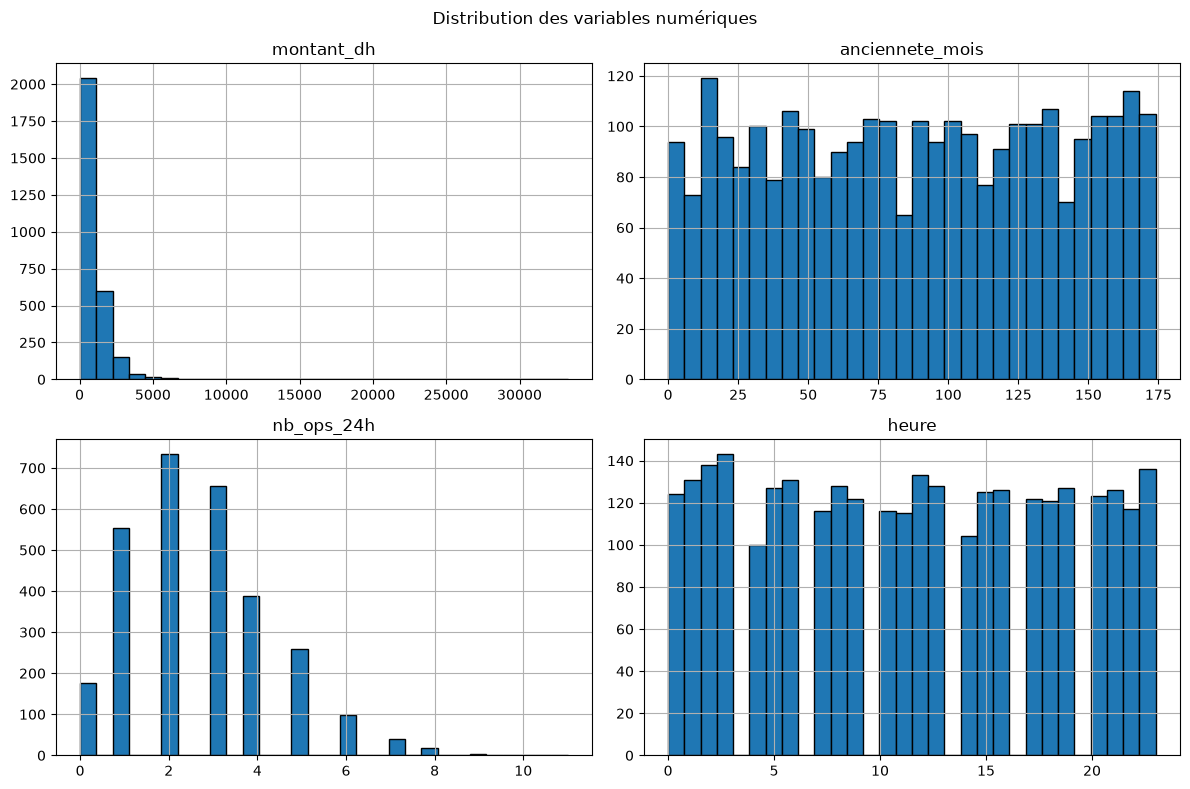

In [23]:
variables_num = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"]

df[variables_num].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution des variables numériques")
plt.tight_layout()
plt.show()


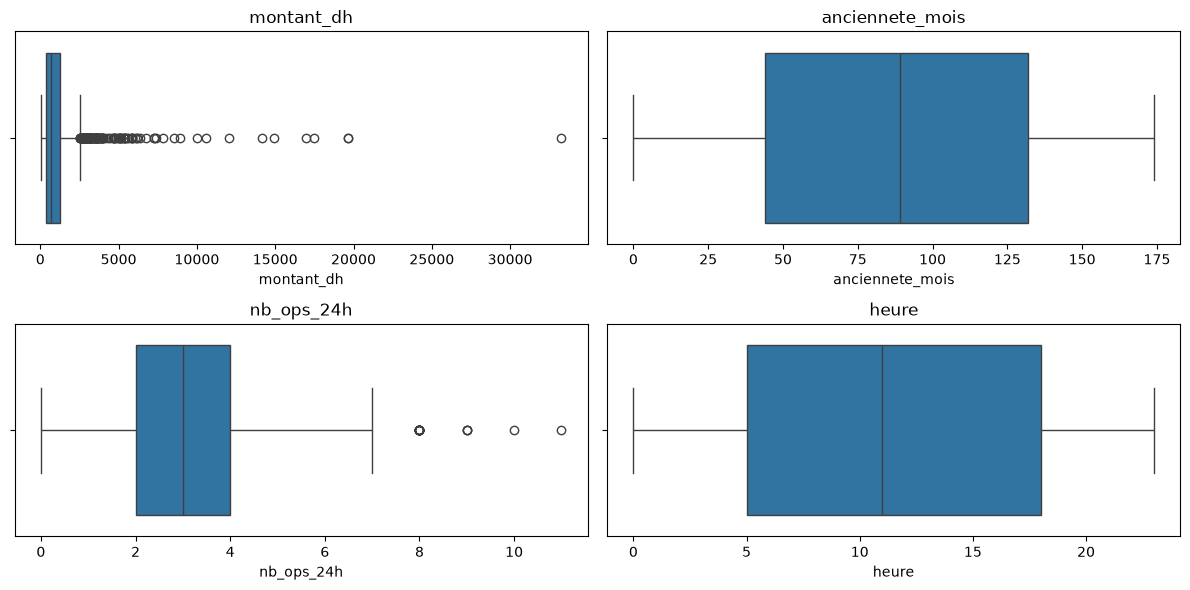

In [24]:

plt.figure(figsize=(12, 6))

for i, colonne in enumerate(variables_num):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x=df[colonne])
    plt.title(colonne)

plt.tight_layout()
plt.show()


fraude
0    2719
1     260
Name: count, dtype: int64

Pourcentages :
fraude
0    91.272239
1     8.727761
Name: proportion, dtype: float64


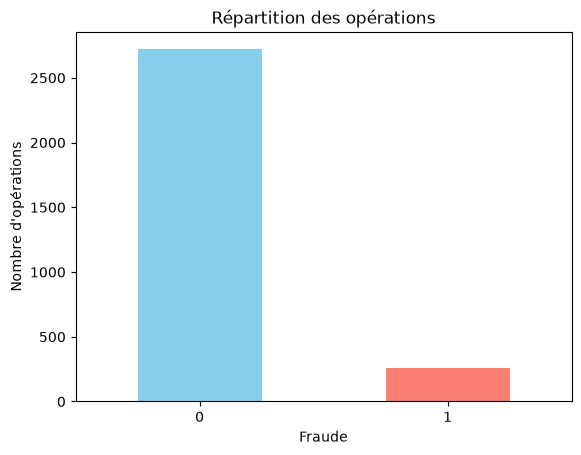

In [25]:
print(df["fraude"].value_counts())

print("\nPourcentages :")
print(df["fraude"].value_counts(normalize=True) * 100)
df["fraude"].value_counts().plot(
    kind="bar",
    color=["skyblue", "salmon"])
plt.title("Répartition des opérations")
plt.xlabel("Fraude")
plt.ylabel("Nombre d'opérations")
plt.xticks(rotation=0)
plt.show()


In [29]:
X = df.drop(
    columns=["id_operation", "id_client", "resultat_enquete", "fraude"])
            

y = df["fraude"]
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print("\nVariables explicatives :")
print(X.columns.tolist())


Dimensions de X : (2979, 8)
Dimensions de y : (2979,)

Variables explicatives :
['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure', 'canal', 'appareil', 'region', 'international']


In [8]:
# partie 2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Downloads/transactions_TP2.csv")

print(df.head())


  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [9]:
X = df.drop(
    columns=["id_operation", "id_client",
             "resultat_enquete", "fraude"]
)

y = df["fraude"]

print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Dimensions de X : (2979, 8)
Dimensions de y : (2979,)


In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print("Dimensions de y_train :", y_train.shape)
print("Dimensions de y_test :", y_test.shape)


Dimensions de X_train : (2383, 8)
Dimensions de X_test : (596, 8)
Dimensions de y_train : (2383,)
Dimensions de y_test : (596,)


In [13]:
variables_num = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"]

variables_cat = [
    "canal",
    "appareil",
    "region",
    "international"]
print("Variables numériques :", variables_num)
print("Variables catégorielles :", variables_cat)


Variables numériques : ['montant_dh', 'anciennete_mois', 'nb_ops_24h', 'heure']
Variables catégorielles : ['canal', 'appareil', 'region', 'international']


In [14]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

pipeline_num = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])
print("Pipeline numérique créé avec succès.")


Pipeline numérique créé avec succès.


In [15]:
from sklearn.preprocessing import OneHotEncoder
pipeline_cat = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

print("Pipeline catégoriel créé avec succès.")


Pipeline catégoriel créé avec succès.


In [16]:
from sklearn.compose import ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", pipeline_num, variables_num),
        ("cat", pipeline_cat, variables_cat) ])

print("ColumnTransformer créé avec succès.")


ColumnTransformer créé avec succès.


In [17]:
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Dimensions après prétraitement :")
print("X_train_prepared :", X_train_prepared.shape)
print("X_test_prepared :", X_test_prepared.shape)


Dimensions après prétraitement :
X_train_prepared : (2383, 18)
X_test_prepared : (596, 18)


In [18]:

print("Répartition des classes dans Train :")
print(y_train.value_counts(normalize=True) * 100)

print("\nRépartition des classes dans Test :")
print(y_test.value_counts(normalize=True) * 100)


Répartition des classes dans Train :
fraude
0    91.271507
1     8.728493
Name: proportion, dtype: float64

Répartition des classes dans Test :
fraude
0    91.275168
1     8.724832
Name: proportion, dtype: float64


In [20]:

from sklearn.preprocessing import RobustScaler

imputer = SimpleImputer(strategy="median")
X_train_num_imputed = imputer.fit_transform(X_train[variables_num])
scaler_standard = StandardScaler()
X_standard = scaler_standard.fit_transform(X_train_num_imputed)

scaler_robust = RobustScaler()
X_robust = scaler_robust.fit_transform(X_train_num_imputed)

print("Premières valeurs avec StandardScaler :")
print(X_standard[:5])
print("\nPremières valeurs avec RobustScaler :")
print(X_robust[:5])


Premières valeurs avec StandardScaler :
[[ 1.04588396  1.37509704  0.19436654 -0.79098066]
 [-0.43103753  0.47083735 -1.64606576  0.06482271]
 [-0.58068311 -0.25257039  0.80784397  1.63379554]
 [-0.56482513 -1.45824997  0.19436654 -0.07781119]
 [ 0.27291314 -0.45351699  0.80784397 -0.64834677]]

Premières valeurs avec RobustScaler :
[[ 2.21340938  0.8         0.5        -0.46153846]
 [-0.35281617  0.27058824 -1.          0.        ]
 [-0.6128329  -0.15294118  1.          0.84615385]
 [-0.58527887 -0.85882353  0.5        -0.07692308]
 [ 0.87033362 -0.27058824  1.         -0.38461538]]


In [21]:
print("X_train_prepared :", X_train_prepared.shape)
print("X_test_prepared :", X_test_prepared.shape)

X_train_prepared : (2383, 18)
X_test_prepared : (596, 18)


In [22]:
# PARTIE 3 : Comparaison des méthodes de Scaling
montants = X_train["montant_dh"].dropna()

Q1 = montants.quantile(0.25)
Q3 = montants.quantile(0.75)

IQR = Q3 - Q1

borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

outliers = montants[
    (montants < borne_inf) | (montants > borne_sup)]

print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Borne inférieure :", borne_inf)
print("Borne supérieure :", borne_sup)
print("Nombre d'outliers :", len(outliers))


Q1 : 390.29999999999995
Q3 : 1251.955
IQR : 861.655
Borne inférieure : -902.1825000000001
Borne supérieure : 2544.4375
Nombre d'outliers : 140


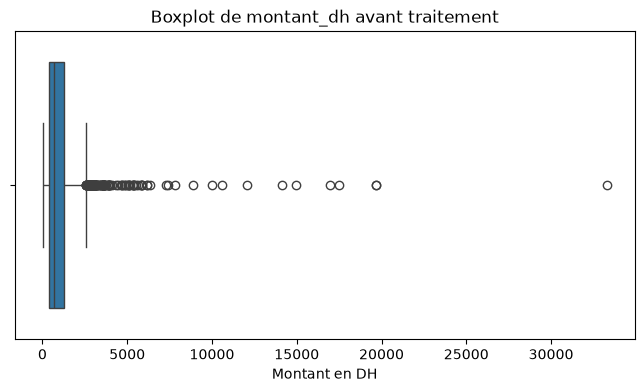

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))

sns.boxplot(x=X_train["montant_dh"])

plt.title("Boxplot de montant_dh avant traitement")
plt.xlabel("Montant en DH")

plt.show()


In [27]:
X_train_clip = X_train.copy()
X_test_clip = X_test.copy()

X_train_clip["montant_dh"] = X_train_clip["montant_dh"].clip(
    lower=borne_inf,
    upper=borne_sup)

X_test_clip["montant_dh"] = X_test_clip["montant_dh"].clip(
    lower=borne_inf,
    upper=borne_sup)
print("Avant Clipping :")
print(X_train["montant_dh"].describe())

print("\nAprès Clipping :")
print(X_train_clip["montant_dh"].describe())


Avant Clipping :
count     2299.000000
mean      1042.986568
std       1447.323491
min         36.410000
25%        390.300000
50%        706.800000
75%       1251.955000
max      33281.230000
Name: montant_dh, dtype: float64

Après Clipping :
count    2299.000000
mean      914.606886
std       676.865052
min        36.410000
25%       390.300000
50%       706.800000
75%      1251.955000
max      2544.437500
Name: montant_dh, dtype: float64


In [28]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
imputer_montant = SimpleImputer(strategy="median")

train_montant = imputer_montant.fit_transform(
    X_train[["montant_dh"]])

test_montant = imputer_montant.transform(
    X_test[["montant_dh"]])

scaler_minmax = MinMaxScaler()

train_minmax = scaler_minmax.fit_transform(train_montant)
test_minmax = scaler_minmax.transform(test_montant)

scaler_standard = StandardScaler()

train_standard = scaler_standard.fit_transform(train_montant)
test_standard = scaler_standard.transform(test_montant)

scaler_robust = RobustScaler()
train_robust = scaler_robust.fit_transform(train_montant)
test_robust = scaler_robust.transform(test_montant)

print("MinMaxScaler :", train_minmax[:5].flatten())
print("StandardScaler :", train_standard[:5].flatten())
print("RobustScaler :", train_robust[:5].flatten())


MinMaxScaler : [0.0746772  0.01147607 0.00507237 0.00575097 0.04159986]
StandardScaler : [ 1.04588396 -0.43103753 -0.58068311 -0.56482513  0.27291314]
RobustScaler : [ 2.21340938 -0.35281617 -0.6128329  -0.58527887  0.87033362]


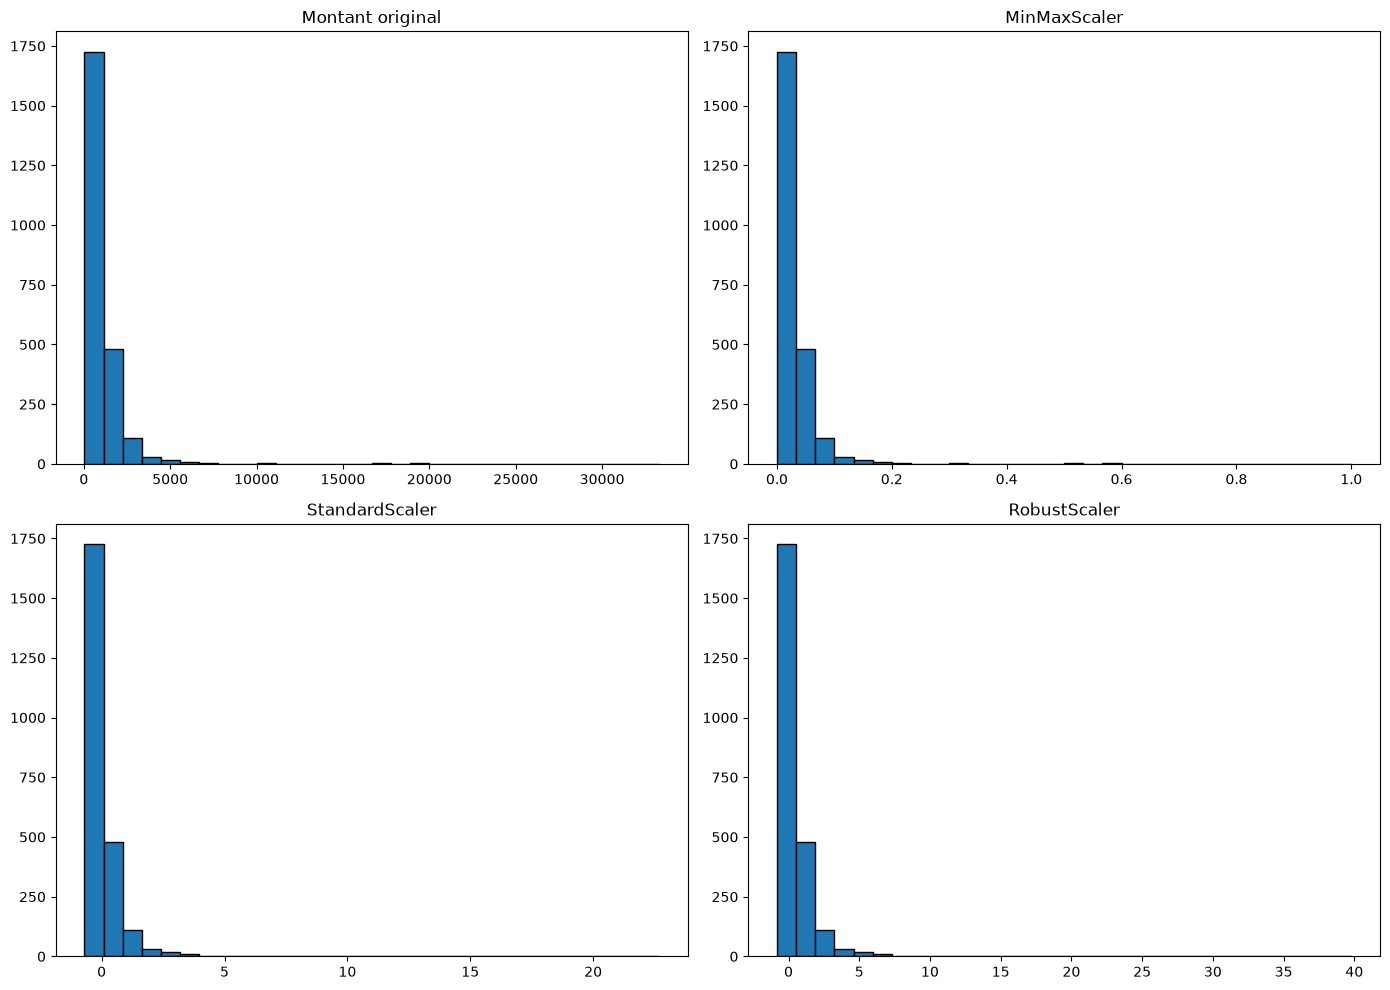

In [29]:
plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.hist(train_montant.flatten(), bins=30, edgecolor="black")
plt.title("Montant original")

plt.subplot(2, 2, 2)
plt.hist(train_minmax.flatten(), bins=30, edgecolor="black")
plt.title("MinMaxScaler")

plt.subplot(2, 2, 3)
plt.hist(train_standard.flatten(), bins=30, edgecolor="black")
plt.title("StandardScaler")

plt.subplot(2, 2, 4)
plt.hist(train_robust.flatten(), bins=30, edgecolor="black")
plt.title("RobustScaler")
plt.tight_layout()
plt.show()


In [30]:
nb_sup_1 = np.sum(test_minmax > 1)
nb_inf_0 = np.sum(test_minmax < 0)

print("Nombre de valeurs supérieures à 1 :", nb_sup_1)
print("Nombre de valeurs inférieures à 0 :", nb_inf_0)
print("Maximum de Train :", train_minmax.max())
print("Maximum de Test :", test_minmax.max())


Nombre de valeurs supérieures à 1 : 0
Nombre de valeurs inférieures à 0 : 0
Maximum de Train : 1.0
Maximum de Test : 0.2550111566253028


In [31]:
print("Q1 :", Q1)
print("Q3 :", Q3)
print("IQR :", IQR)
print("Nombre d'outliers :", len(outliers))

print("Nombre de valeurs supérieures à 1 :", nb_sup_1)
print("Maximum de Test :", test_minmax.max())

Q1 : 390.29999999999995
Q3 : 1251.955
IQR : 861.655
Nombre d'outliers : 140
Nombre de valeurs supérieures à 1 : 0
Maximum de Test : 0.2550111566253028


In [34]:
# PARTIE 4 : 
print("Distribution avant équilibrage :")
print(y_train.value_counts())

print("\nPourcentage :")
print(y_train.value_counts(normalize=True) * 100)

Distribution avant équilibrage :
fraude
0    2175
1     208
Name: count, dtype: int64

Pourcentage :
fraude
0    91.271507
1     8.728493
Name: proportion, dtype: float64


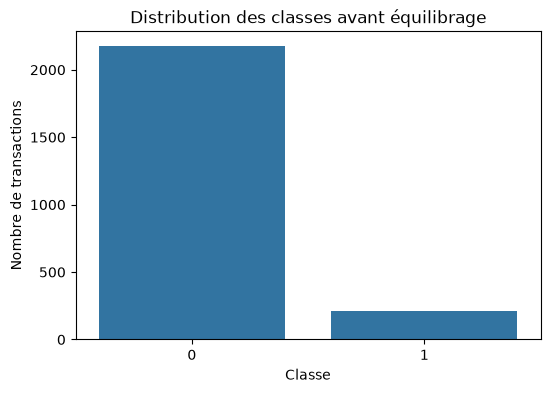

In [35]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y_train)
plt.title("Distribution des classes avant équilibrage")
plt.xlabel("Classe")
plt.ylabel("Nombre de transactions")
plt.show()

In [36]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros.fit_resample(
    X_train_prepared,
    y_train)

print("Avant OverSampling :")
print(y_train.value_counts())
print("\nAprès OverSampling :")
print(y_train_over.value_counts())

Avant OverSampling :
fraude
0    2175
1     208
Name: count, dtype: int64

Après OverSampling :
fraude
0    2175
1    2175
Name: count, dtype: int64


In [37]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(
    X_train_prepared,
    y_train)

print("Avant UnderSampling :")
print(y_train.value_counts())
print("\nAprès UnderSampling :")
print(y_train_under.value_counts())

Avant UnderSampling :
fraude
0    2175
1     208
Name: count, dtype: int64

Après UnderSampling :
fraude
0    208
1    208
Name: count, dtype: int64


In [38]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_prepared,
    y_train)

print("Avant SMOTE :")
print(y_train.value_counts())
print("\nAprès SMOTE :")
print(y_train_smote.value_counts())

Avant SMOTE :
fraude
0    2175
1     208
Name: count, dtype: int64

Après SMOTE :
fraude
0    2175
1    2175
Name: count, dtype: int64


In [39]:
print("Distribution de Test :")
print(y_test.value_counts())
print("\nTaille de X_test_prepared :")
print(X_test_prepared.shape)

Distribution de Test :
fraude
0    544
1     52
Name: count, dtype: int64

Taille de X_test_prepared :
(596, 18)


In [1]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

variables_num = [
    "montant_dh",
    "anciennete_mois",
    "nb_ops_24h",
    "heure"]

variables_cat = [
    "canal",
    "appareil",
    "region",
    "international"]

pipeline_num_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())])

pipeline_cat_final = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor_final = ColumnTransformer(transformers=[
    ("num", pipeline_num_final, variables_num),
    ("cat", pipeline_cat_final, variables_cat)])

In [8]:
import pandas as pd # hadchi khas itmsaa7 mn hna 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("Downloads/transactions_TP2.csv")

In [10]:
print(df.head())
print(df.shape)

  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat           non    aucune_fraude   

   fraude  
0       0  
1       0  
2       0  
3       0  
4 

In [11]:
X = df.drop(
    columns=["id_operation", "id_client",
             "resultat_enquete", "fraude"]
)

y = df["fraude"]

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
) # hata lhna 

In [13]:
X_train_final = preprocessor_final.fit_transform(X_train)
X_test_final = preprocessor_final.transform(X_test)

print("Taille de Train :", X_train_final.shape)
print("Taille de Test :", X_test_final.shape)

Taille de Train : (2383, 18)
Taille de Test : (596, 18)


In [14]:
import numpy as np
from scipy import sparse

print("Nombre de colonnes Train :", X_train_final.shape[1])
print("Nombre de colonnes Test :", X_test_final.shape[1])
if sparse.issparse(X_train_final):
    print("Valeurs manquantes Train :", np.isnan(X_train_final.data).sum())
else:
    print("Valeurs manquantes Train :", np.isnan(X_train_final).sum())   
if sparse.issparse(X_test_final):
    print("Valeurs manquantes Test :", np.isnan(X_test_final.data).sum())
else:
    print("Valeurs manquantes Test :", np.isnan(X_test_final).sum())

Nombre de colonnes Train : 18
Nombre de colonnes Test : 18
Valeurs manquantes Train : 0
Valeurs manquantes Test : 0


In [15]:
nouvelle_ligne = X_test.iloc[[0]].copy()
nouvelle_ligne.loc[:, "canal"] = "NOUVEAU_CANAL"
nouvelle_ligne_transformee = preprocessor_final.transform( nouvelle_ligne)
print("Transformation réussie !")
print("Taille :", nouvelle_ligne_transformee.shape)

Transformation réussie !
Taille : (1, 18)


In [16]:
import joblib
joblib.dump(preprocessor_final, "preprocessor_final.pkl")
print("Transformateur enregistré avec succès.")

Transformateur enregistré avec succès.


In [17]:
preprocessor_charge = joblib.load("preprocessor_final.pkl")
print("Transformateur rechargé avec succès.")

Transformateur rechargé avec succès.


In [18]:
echantillon = X_test.iloc[:5]
resultat_original = preprocessor_final.transform(echantillon)
resultat_charge = preprocessor_charge.transform(echantillon)
if sparse.issparse(resultat_original):
    difference = resultat_original - resultat_charge
    identiques = np.allclose(difference.data, 0)
else:
    identiques = np.allclose(resultat_original, resultat_charge)
print("Les deux résultats sont identiques :", identiques)

Les deux résultats sont identiques : True


In [20]:
montants = X_train["montant_dh"].dropna()# hadchi khas itmsaa7
Q1 = montants.quantile(0.25)
Q3 = montants.quantile(0.75)
IQR = Q3 - Q1
borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR
outliers = montants[
    (montants < borne_inf) | (montants > borne_sup)]
print("Nombre d'outliers :", len(outliers))

Nombre d'outliers : 140


In [21]:
print("Doublons détectés :",
      df["id_operation"].duplicated().sum())
colonnes_utiles = variables_num + variables_cat
print("Valeurs manquantes initiales :",
      df[colonnes_utiles].isnull().sum().sum())
print("Valeurs aberrantes dans montant_dh :", len(outliers))
print("\nAvant équilibrage :")
print(y_train.value_counts())
print("\nAprès RandomOverSampler :")
print(y_train_over.value_counts())
print("\nAprès RandomUnderSampler :")
print(y_train_under.value_counts())
print("\nAprès SMOTE :")
print(y_train_smote.value_counts())

Doublons détectés : 43
Valeurs manquantes initiales : 666
Valeurs aberrantes dans montant_dh : 140

Avant équilibrage :
fraude
0    2175
1     208
Name: count, dtype: int64

Après RandomOverSampler :


NameError: name 'y_train_over' is not defined

In [23]:
import numpy as np
from scipy import sparse
if sparse.issparse(X_train_final):
    missing_train = np.isnan(X_train_final.data).sum()
else:
    missing_train = np.isnan(X_train_final).sum()
if sparse.issparse(X_test_final):
    missing_test = np.isnan(X_test_final.data).sum()
else:
    missing_test = np.isnan(X_test_final).sum()
print("Missing values dans Train :", missing_train)
print("Missing values dans Test :", missing_test)

Missing values dans Train : 0
Missing values dans Test : 0


In [24]:
nouvelle_ligne = X_test.iloc[[0]].copy()
nouvelle_ligne["canal"] = nouvelle_ligne["canal"].astype("object")
nouvelle_ligne.loc[:, "canal"] = "NOUVEAU_CANAL"
nouvelle_ligne_transformee = preprocessor_final.transform(nouvelle_ligne)
print("Transformation réussie !")
print("Dimension :", nouvelle_ligne_transformee.shape)

Transformation réussie !
Dimension : (1, 18)


In [25]:
import joblib
joblib.dump(preprocessor_final, "preprocessor_final.pkl")
print("Préprocesseur sauvegardé avec succès !")

Préprocesseur sauvegardé avec succès !


In [26]:
preprocessor_charge = joblib.load("preprocessor_final.pkl")
print("Préprocesseur chargé avec succès !")

Préprocesseur chargé avec succès !


In [27]:
echantillon = X_test.iloc[:5]
resultat_original = preprocessor_final.transform(echantillon)
resultat_charge = preprocessor_charge.transform(echantillon)
if sparse.issparse(resultat_original):
    difference = resultat_original - resultat_charge
    identiques = np.allclose(difference.data, 0)
else:
    identiques = np.allclose(resultat_original, resultat_charge)
print("Les deux résultats sont identiques :", identiques)

Les deux résultats sont identiques : True
